11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.9412 - loss: 0.2025
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9838 - loss: 0.0530
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9887 - loss: 0.0372
Defense Epoch: 1 Loss: 0.1347
Defense Epoch: 2 Loss: 0.1983

Model Performance
Original Clean Accuracy: 0.9858
Original Adversarial Accuracy: 0.6293
Defended Clean Accuracy: 0.9851
Defended Adversarial Accuracy: 0.9173
Robustness Improvement: 0.288


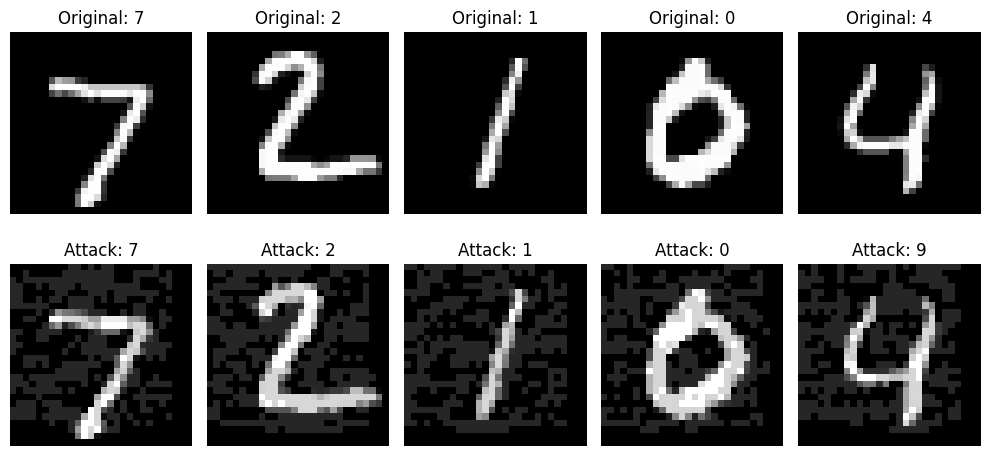

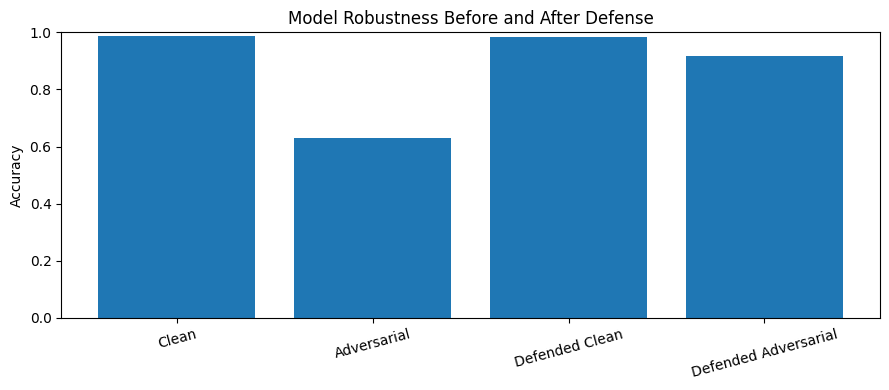

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

def build_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10)])
    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"])
    return model
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def fgsm_attack(model, images, labels, epsilon=0.15):
    images = tf.convert_to_tensor(images)

    with tf.GradientTape() as tape:
        tape.watch(images)
        predictions = model(images, training=False)
        loss = loss_fn(labels, predictions)

    gradients = tape.gradient(loss, images)
    adversarial_images = images + epsilon * tf.sign(gradients)
    return tf.clip_by_value(adversarial_images, 0, 1)

model = build_model()
model.fit(x_train, y_train, epochs=3, batch_size=128, verbose=1)
clean_loss, clean_accuracy = model.evaluate(x_test, y_test, verbose=0)
x_test_adv = fgsm_attack(model, x_test, y_test, epsilon=0.15)
adv_predictions = np.argmax(model.predict(x_test_adv, verbose=0), axis=1)
adv_accuracy = np.mean(adv_predictions == y_test)
defended_model = build_model()
optimizer = tf.keras.optimizers.Adam()

train_dataset = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)).shuffle(10000).batch(128).prefetch(tf.data.AUTOTUNE)

for epoch in range(2):
    for images, labels in train_dataset:
        adv_images = fgsm_attack(defended_model, images, labels, epsilon=0.15)
        combined_images = tf.concat([images, adv_images], axis=0)
        combined_labels = tf.concat([labels, labels], axis=0)
        with tf.GradientTape() as tape:
            predictions = defended_model(combined_images, training=True)
            loss = loss_fn(combined_labels, predictions)
        gradients = tape.gradient(loss, defended_model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, defended_model.trainable_variables))

    print("Defense Epoch:", epoch + 1, "Loss:", round(float(loss), 4))

_, defended_clean_accuracy = defended_model.evaluate(
    x_test, y_test, verbose=0)

x_test_adv_defended = fgsm_attack(
    defended_model, x_test, y_test, epsilon=0.15)

defended_adv_predictions = np.argmax(
    defended_model.predict(x_test_adv_defended, verbose=0), axis=1)

defended_adv_accuracy = np.mean(defended_adv_predictions == y_test)

print("\nModel Performance")
print("Original Clean Accuracy:", round(clean_accuracy, 4))
print("Original Adversarial Accuracy:", round(adv_accuracy, 4))
print("Defended Clean Accuracy:", round(defended_clean_accuracy, 4))
print("Defended Adversarial Accuracy:", round(defended_adv_accuracy, 4))
print("Robustness Improvement:", round(defended_adv_accuracy - adv_accuracy, 4))

plt.figure(figsize=(10, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title("Original: " + str(y_test[i]))
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(x_test_adv[i].numpy().squeeze(), cmap="gray")
    plt.title("Attack: " + str(adv_predictions[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

labels = ["Clean", "Adversarial", "Defended Clean", "Defended Adversarial"]
accuracies = [
    clean_accuracy,
    adv_accuracy,
    defended_clean_accuracy,
    defended_adv_accuracy]

plt.figure(figsize=(9, 4))
plt.bar(labels, accuracies)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Model Robustness Before and After Defense")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()